# 08 · Robustez de los resultados

Se reestiman las pruebas de H2 y H3 bajo tres especificaciones alternativas (500 remuestras bootstrap y 500 permutaciones en cada una):

| Especificación | Qué cambia | Por qué |
|---|---|---|
| **Principal** | IPC, tendencia OLS, sin atípicos monetarios | Especificación de referencia |
| **Deflactor** | Variable dependiente: deflactor del PIB | Otra medida de inflación; incluye Argentina, Cuba, Somalia y Turkmenistán |
| **Theil-Sen** | Tendencia estimada con pendiente robusta | Evitar que un solo año extremo determine la tendencia (por ejemplo, Zimbabue 2020) |
| **Con atípicos** | Se reincorporan los 8 atípicos monetarios | Evaluar si la exclusión determina los resultados |

La robustez de H1 frente a la configuración de clustering está en el notebook 06 (sección 5).

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
VAR = {"": "Principal", "_deflactor": "Deflactor", "_theil_sen": "Theil-Sen", "_con_atipicos": "Con atípicos"}
STAT = {"media": "Media", "tendencia": "Tendencia", "volatilidad": "Volatilidad"}
rows = []
for suf, name in VAR.items():
    for hip in ["h2", "h3"]:
        d = pd.read_csv(D / f"reg_{hip}{suf}.csv").assign(especificacion=name, hip=hip.upper())
        rows.append(d)
R = pd.concat(rows)
R["prueba"] = R["hip"] + " · " + R["estadistico"].map(STAT) + " · " + R["bloque"].map(lambda b: DIM_LABELS.get(b, "No monetarias"))
for suf, name in VAR.items():
    d = pd.read_csv(D / f"reg_diagnosticos{suf}.csv")
    print(name, "· n por modelo:", d.groupby("estadistico")["n"].first().to_dict())

Principal · n por modelo: {'media': 171, 'tendencia': 171, 'volatilidad': 171}
Deflactor · n por modelo: {'media': 175, 'tendencia': 175, 'volatilidad': 175}
Theil-Sen · n por modelo: {'media': 171, 'tendencia': 171, 'volatilidad': 171}
Con atípicos · n por modelo: {'media': 178, 'tendencia': 178, 'volatilidad': 178}


## 1. Solidez de cada prueba en las cuatro especificaciones

Una prueba se considera **sólida** si p_HC3 < 0,05, p de permutación < 0,05 y el límite inferior del IC 95% del ΔR² ajustado es mayor que 0. La cifra en cada celda es el p de permutación.

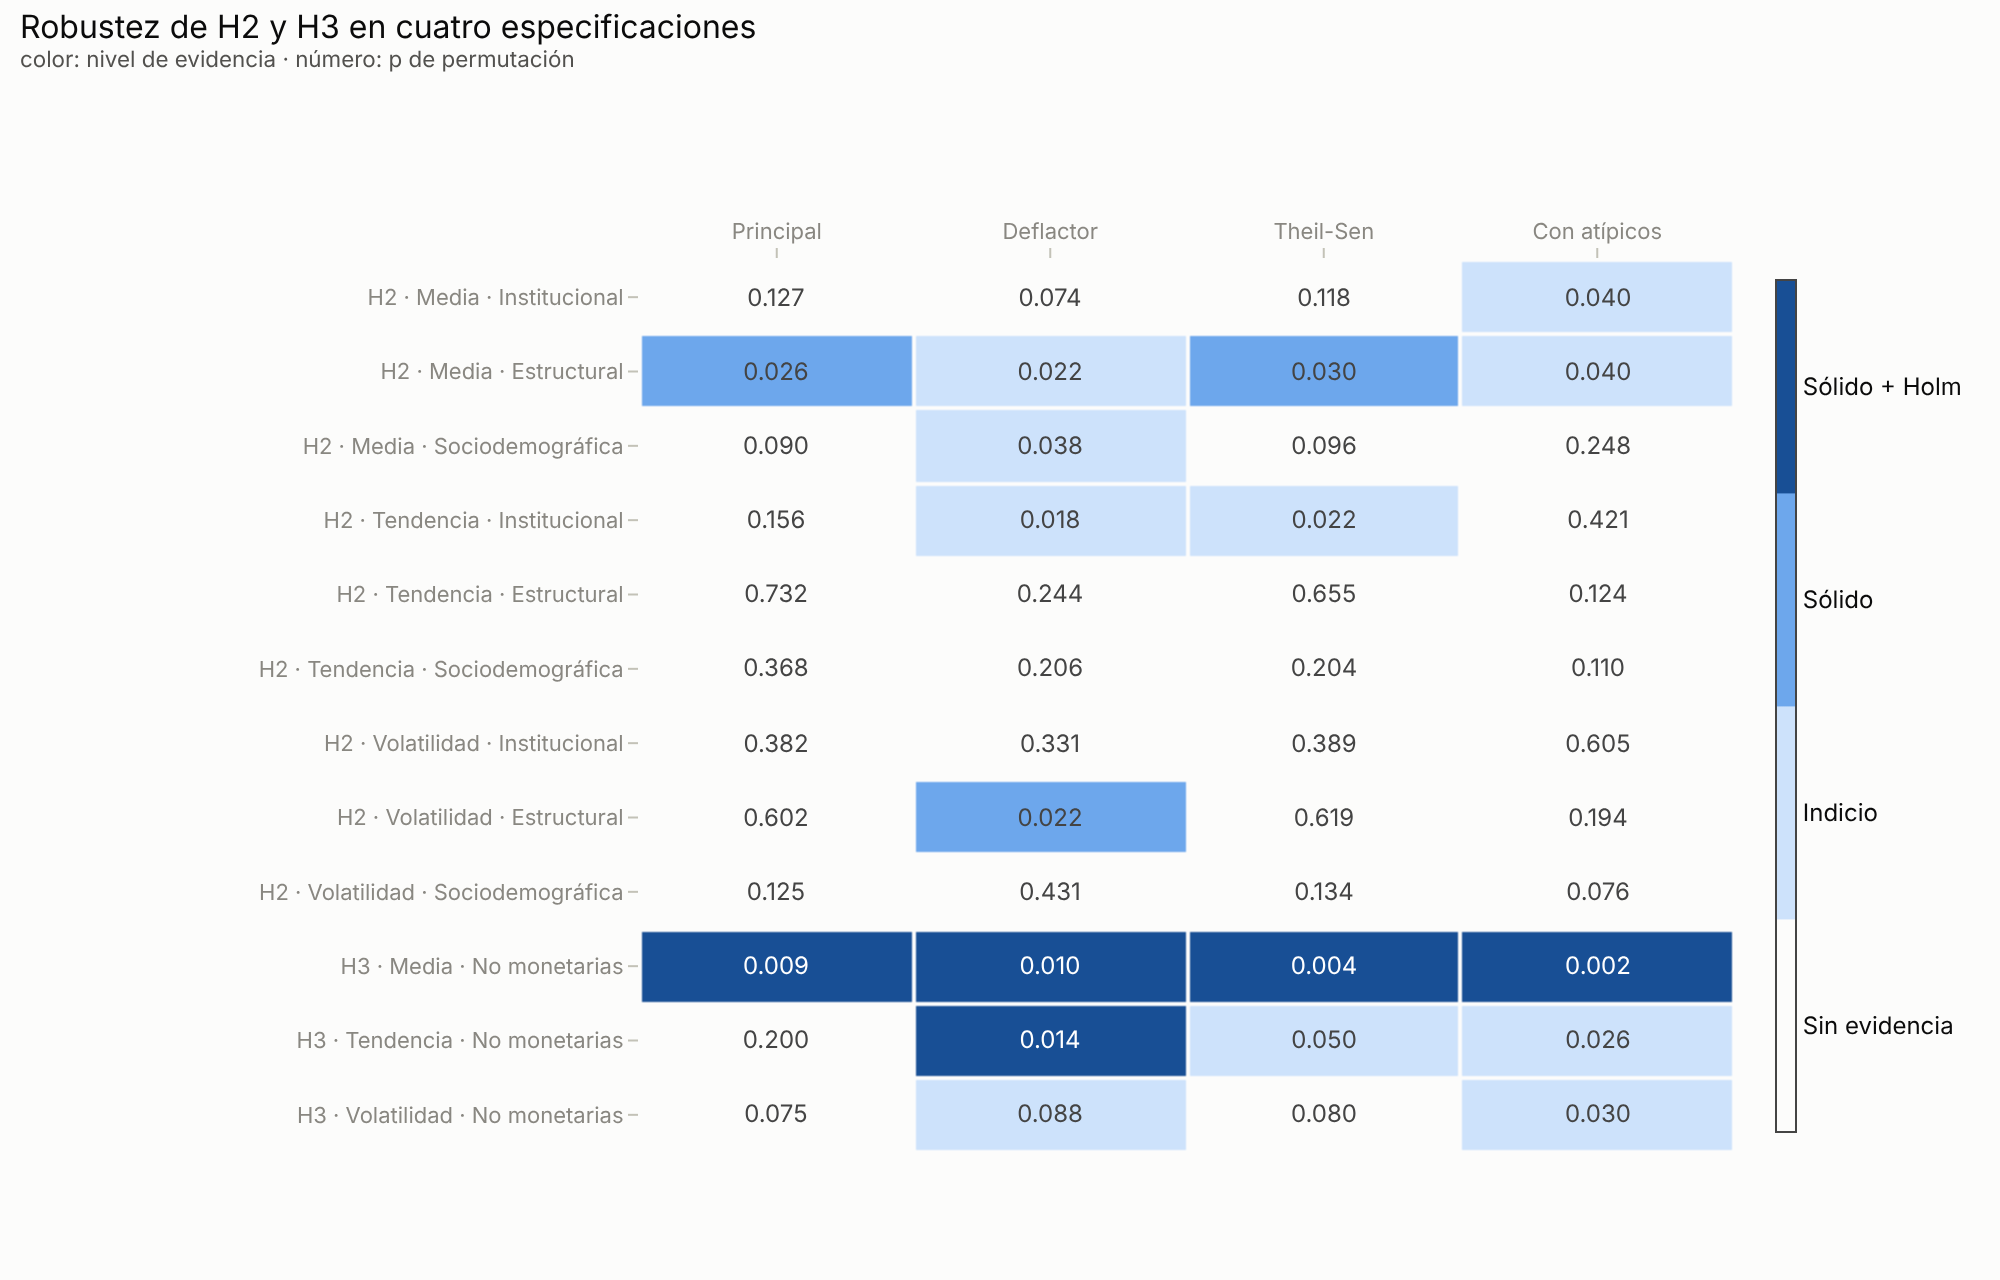

In [2]:
def level(r):
    if r["solido"] and r["p_HC3_holm"] < 0.05:
        return 3
    if r["solido"]:
        return 2
    if min(r["p"], r["p_HC3"], r["p_permutacion"]) < 0.05:
        return 1
    return 0
R["nivel"] = R.apply(level, axis=1)
M = R.pivot(index="prueba", columns="especificacion", values="nivel")[list(VAR.values())]
Pp = R.pivot(index="prueba", columns="especificacion", values="p_permutacion")[list(VAR.values())]
order = R.drop_duplicates("prueba")["prueba"].tolist()
M, Pp = M.loc[order], Pp.loc[order]
cs = [[0, "#fcfcfb"], [0.249, "#fcfcfb"], [0.25, "#cde2fb"], [0.499, "#cde2fb"], [0.5, "#6da7ec"], [0.749, "#6da7ec"], [0.75, "#184f95"], [1, "#184f95"]]
fig = go.Figure(go.Heatmap(z=M.values, x=list(M.columns), y=list(M.index), zmin=-0.5, zmax=3.5, colorscale=cs,
                           text=Pp.map(lambda v: f"{v:.3f}").values, texttemplate="%{text}", xgap=2, ygap=2,
                           hovertemplate="%{y} · %{x}: p perm. %{text}<extra></extra>",
                           colorbar=dict(tickvals=[0, 1, 2, 3], ticktext=["Sin evidencia", "Indicio", "Sólido", "Sólido + Holm"], thickness=10)))
fig.update_layout(title=subtitle("Robustez de H2 y H3 en cuatro especificaciones", "color: nivel de evidencia · número: p de permutación"),
                  xaxis=dict(side="top", showgrid=False), yaxis=dict(autorange="reversed", showgrid=False), margin=dict(l=320, t=130))
show(fig, "08_robustez_matriz", width=1000, height=640)

**Interpretación.**

- **H3 para la media es el único resultado sólido y robusto a Holm en las cuatro especificaciones** (p de permutación entre 0,002 y 0,010). Es la conclusión principal del análisis.
- **H2 estructural sobre la media** es sólido en la principal y en Theil-Sen. En las especificaciones con el deflactor y con los atípicos queda como indicio: los p-valores siguen debajo de 0,05, pero el intervalo del ΔR² toca el cero. Es evidencia consistente en dirección, pero no plenamente robusta.
- **H3 para la tendencia** es sólido solo con el deflactor, la especificación que incluye a Argentina y a otros casos de alta inflación. En las demás queda en indicio o sin evidencia. La tendencia del deflactor está más expuesta a los términos de intercambio (notebook 03), así que este resultado no se generaliza.
- El resto de las pruebas de H2 aparecen como indicios aislados en alguna especificación, sin un patrón estable.

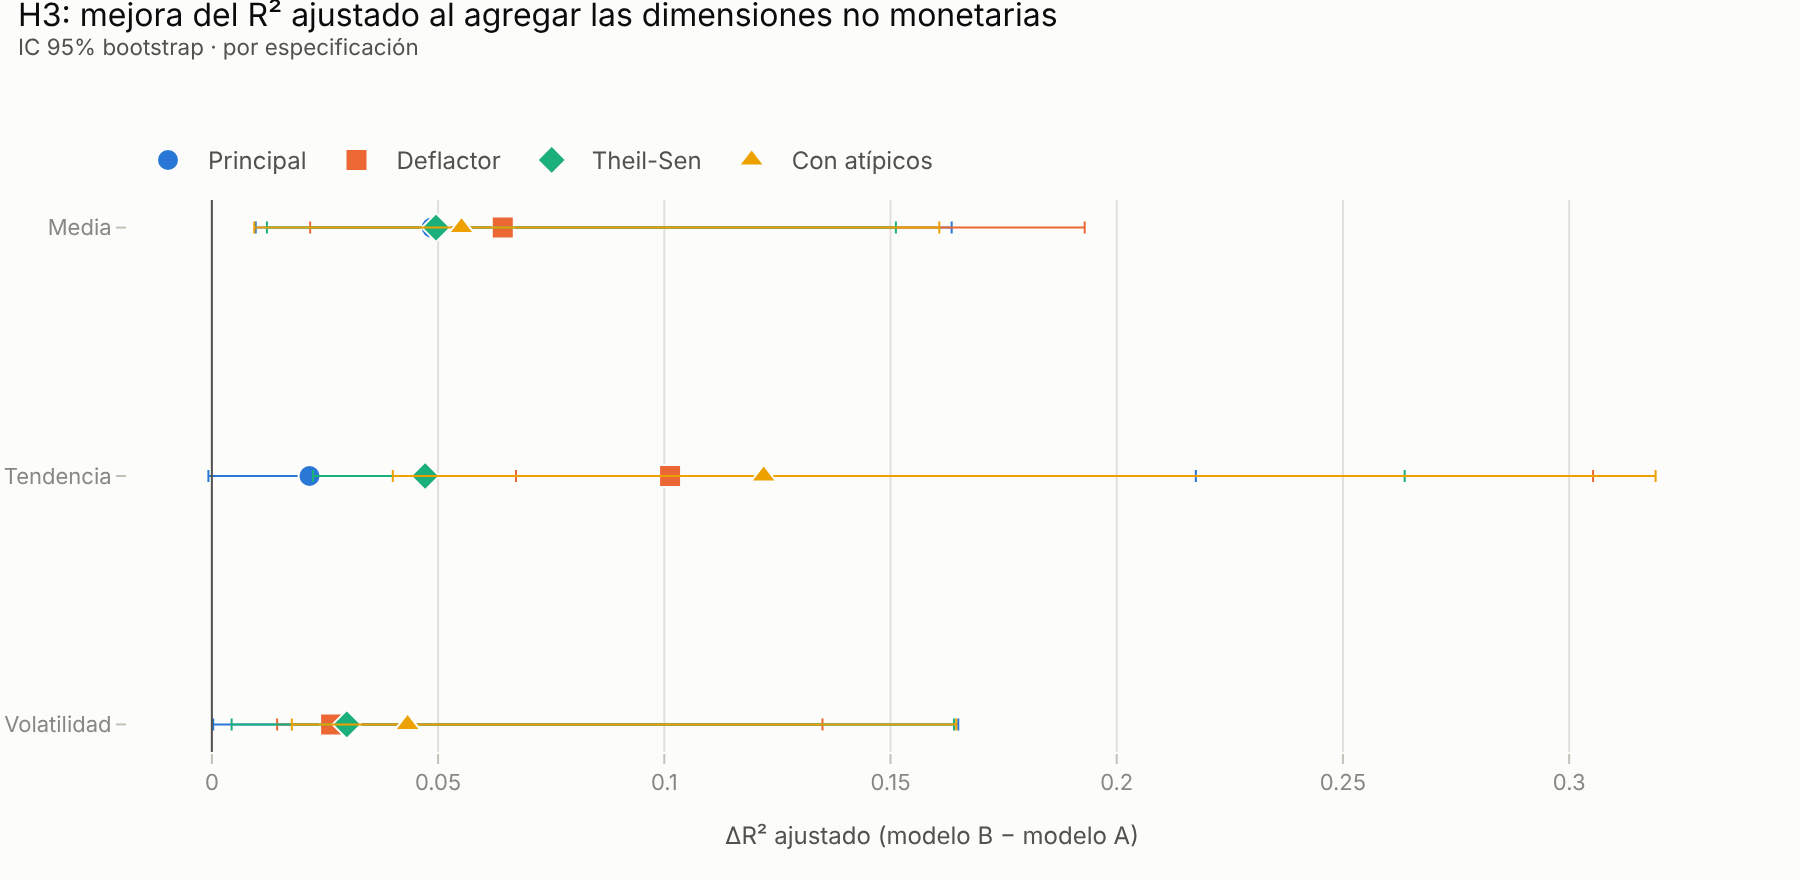

r2adj_restringido                       r2adj_completo  \
estadistico                media tendencia volatilidad          media   
especificacion                                                          
Principal                  0.243     0.068       0.329          0.292   
Deflactor                  0.162     0.064       0.389          0.226   
Theil-Sen                  0.243     0.094       0.329          0.292   
Con atípicos               0.252     0.065       0.330          0.306   

                                      p_HC3                        \
estadistico    tendencia volatilidad  media tendencia volatilidad   
especificacion                                                      
Principal          0.090       0.358  0.003     0.493       0.251   
Deflactor          0.166       0.415  0.000     0.022       0.029   
Theil-Sen          0.141       0.358  0.003     0.530       0.251   
Con atípicos       0.186       0.373  0.001     0.425       0.096   

               p_permutacion                        
estadistico            media tendencia volatilidad  
especificacion                                      
Principal              0.009     0.200       0.075  
Deflactor              0.010     0.014       0.088  
Theil-Sen              0.004     0.050       0.080  
Con atípicos           0.002     0.026       0.030

In [3]:
h3 = R[R["hip"] == "H3"]
fig = go.Figure()
for i, (spec, g) in enumerate(h3.groupby("especificacion", sort=False)):
    fig.add_scatter(x=g["delta_r2adj"], y=g["estadistico"].map(STAT), mode="markers", name=spec,
                    marker=dict(size=11, color=CATEGORICAL[i], symbol=["circle", "square", "diamond", "triangle-up"][i]),
                    error_x=dict(type="data", symmetric=False, array=g["delta_ic95_sup"] - g["delta_r2adj"], arrayminus=g["delta_r2adj"] - g["delta_ic95_inf"],
                                 color=CATEGORICAL[i], thickness=1, width=3),
                    hovertemplate=spec + " · %{y}: ΔR² aj. %{x:.3f}<extra></extra>")
fig.add_vline(x=0, line=dict(color=INK_SECONDARY, width=1))
fig.update_layout(scattermode="group", title=subtitle("H3: mejora del R² ajustado al agregar las dimensiones no monetarias", "IC 95% bootstrap · por especificación"),
                  xaxis=dict(title="ΔR² ajustado (modelo B − modelo A)"), yaxis=dict(showgrid=False, autorange="reversed"))
show(fig, "08_h3_delta_r2", height=440)
h3.pivot(index="especificacion", columns="estadistico", values=["r2adj_restringido", "r2adj_completo", "p_HC3", "p_permutacion"]).round(3).loc[list(VAR.values())]

**Interpretación.** En la media, el modelo con las cuatro dimensiones mejora el R² ajustado en 0,05-0,06 en todas las especificaciones, con intervalos bootstrap que excluyen el cero. En la tendencia y la volatilidad las mejoras son más chicas, varían entre especificaciones y sus intervalos son amplios. La reincorporación de los atípicos no cambia ninguna conclusión: la exclusión de los 8 países atípicos no está produciendo los resultados.

## 2. Comparación con la versión 1 (tesis entregada)

La tesis original reportó estos resultados (sección 4 del documento). La tabla los contrasta con los obtenidos ahora, tras reconstruir el pipeline completo.

In [4]:
cmp = pd.DataFrame({
    "Tesis v1": ["Respaldada (dispersión intra-grupo alta; GMM tied k=4)",
                 "No confirmada (ninguna dimensión robusta en clásico, bootstrap y HC3)",
                 "Parcial: solo volatilidad (R² aj. 0,274 → 0,329)"],
    "Pipeline reconstruido": ["Respaldada: el grupo explica 23% (media), 2% (tendencia) y 31% (volatilidad); robusta en 13 configuraciones (K-means k=5)",
                              "Evidencia moderada solo para la dimensión estructural sobre la media (sólida en 2 de 4 especificaciones, no sobrevive a Holm)",
                              "Parcial: solo media (R² aj. 0,24 → 0,29), sólida y robusta a Holm en las 4 especificaciones"],
}, index=["H1", "H2", "H3"])
cmp

,Tesis v1,Pipeline reconstruido
H1,Respaldada (dispersión intra-grupo alta; GMM t...,"Respaldada: el grupo explica 23% (media), 2% (..."
H2,No confirmada (ninguna dimensión robusta en cl...,Evidencia moderada solo para la dimensión estr...
H3,"Parcial: solo volatilidad (R² aj. 0,274 → 0,329)","Parcial: solo media (R² aj. 0,24 → 0,29), sóli..."


**Por qué cambian los resultados.** Los cambios en H2 y H3 se deben a correcciones del pipeline, no a variaciones aleatorias:

1. **Fuga de información**: en la v1, el IPC, los deflactores y los índices de precios estaban entre las variables monetarias que forman los perfiles y los predictores. En la v2 se excluyen todos.
2. **Comparabilidad**: la v1 conservaba niveles absolutos (totales en US$ o moneda local, poblaciones, conteos) fuera del bloque monetario. La v2 los excluye en todas las dimensiones.
3. **Duplicados**: el mismo índice WGI en dos escalas pesaba doble en el PCA institucional.
4. **Transformación de la media**: log(1 + media/100) casi no corregía la asimetría (4,7 → 4,2). log(media) la lleva a 0,3.
5. **Datos**: WDI se descargó en su versión de octubre de 2026 y la clasificación se rehízo íntegramente con Groq.

Durante la reconstrucción, los resultados de H2 cambiaron con cada una de estas correcciones (por ejemplo, el efecto institucional sobre la tendencia apareció y desapareció). **H3 para la media fue el único resultado estable en todas las versiones intermedias.** Esa sensibilidad de H2 es en sí misma un hallazgo: con 171 países y dimensiones muy colineales, la atribución a una dimensión específica es frágil.

## 3. Limitaciones

- **Selección de la muestra por disponibilidad de datos.** Faltan justamente los casos más extremos: Argentina (IPC solo 2018-2020), Venezuela después de 2016, Zimbabue antes de 2010. La especificación con el deflactor recupera parte de ellos y confirma H3 para la media.
- **Pérdida de información temporal.** Resumir 21 años en tres estadísticos descarta la dinámica (secuencia, rezagos). Los resultados describen asociaciones entre perfiles de largo plazo, no relaciones dinámicas ni causales.
- **Clasificación por LLM.** Coincide 88% con la clasificación manual y 95% con la de la tesis, pero las fronteras entre dimensiones (fiscal-monetaria, empleo) son discutibles. En particular, la regla de "variables fiscales en sentido amplio" lleva el gasto público en salud al bloque monetario, y con él parte del gradiente de desarrollo.
- **Colinealidad entre dimensiones.** Los primeros componentes de las cuatro dimensiones comparten un gradiente de desarrollo (|r| hasta 0,9). Eso vuelve conservadoras las pruebas de H2 y H3 e inestable la atribución a dimensiones específicas.
- **Estructura de grupos débil.** Las silhouettes bajas (≤ 0,27) indican que los perfiles monetario-fiscales forman un continuo. Los grupos son una partición útil, no tipos naturales.

## 4. Extensiones posibles

1. **Panel dinámico**: modelar la inflación año a año con efectos fijos y las dimensiones como moderadoras, en lugar de resumir las trayectorias.
2. **Variable dependiente con más cobertura**: completar Argentina y Venezuela con fuentes alternativas (FMI WEO, institutos provinciales) y documentar el empalme.
3. **Codebook V3**: acotar la regla fiscal al gasto y financiamiento agregados, y validarla contra una muestra nueva clasificada a mano antes de ver la salida del modelo.
4. **Modelos regularizados** (elastic net sobre los indicadores originales, con validación cruzada) como contraste del enfoque PCA + MCO.